# Bay Area Transit and VMT: Exploratory Data Analysis

This notebook characterizes the cleaned public datasets in `data/`. It compares published annual regional ridership and VMT as descriptive trends, explores BART station-pair and time-of-day patterns, and checks the structure of the 2021 SFMTA survey.

The datasets do not share one geography or cadence: BART is monthly station-to-station trips, MTC ridership and VMT are annual regional/county indicators, and the SFMTA data are weighted survey responses. Overlaps are useful for hypothesis generation, not causal attribution. Survey response fields are coded and are not interpreted here without the questionnaire codebook.

In [11]:
# Sections 1-2: environment check, imports, endpoints, and local paths
import gzip
import io
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow
import requests

root_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((path for path in root_candidates if (path / "data").is_dir()), Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR
OUTPUT_DIR = DATA_DIR / "curated"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MTC_ENDPOINTS = {
    "mtc_transit_ridership_by_operator": "https://data.bayareametro.gov/resource/8yy6-v2qd.json",
    "mtc_transit_ridership_by_mode": "https://data.bayareametro.gov/resource/aei4-5fzf.json",
    "mtc_transit_ridership_region": "https://data.bayareametro.gov/resource/t2mj-tpzf.json",
    "mtc_vmt_by_county": "https://data.bayareametro.gov/resource/avsp-dwpp.json",
    "mtc_vmt_region": "https://data.bayareametro.gov/resource/ruva-qh74.json",
}
BART_OD_URL = "https://afcweb.bart.gov/ridership/origin-destination/date-hour-soo-dest-{year}.csv.gz"
SFMTA_SURVEY_XLSX_URL = "https://data.sf.gov/api/views/b7eg-vqw2/files/58cbdef4-865c-4cb3-86ad-335e2c808591?download=true&filename=TDS_2021_data.xlsx"
REFRESH_SOURCES = False
BART_REFRESH_YEARS = []  # Example: [2025]; raw archives are large, so refresh explicitly.

print({"python": sys.version.split()[0], "pandas": pd.__version__, "pyarrow": pyarrow.__version__, "requests": requests.__version__, "matplotlib": plt.matplotlib.__version__})
print({"working_directory": str(Path.cwd()), "project_root": str(PROJECT_ROOT), "data_exists": DATA_DIR.is_dir(), "output_dir": str(OUTPUT_DIR)})

{'python': '3.14.4', 'pandas': '3.0.6', 'pyarrow': '25.0.1', 'requests': '2.34.2', 'matplotlib': '3.11.2'}
{'working_directory': '/home/uttam/Dropbox/Projects/mass_transit_analysis/mass-transit-analysis/notebooks', 'project_root': '/home/uttam/Dropbox/Projects/mass_transit_analysis/mass-transit-analysis', 'data_exists': True, 'output_dir': '/home/uttam/Dropbox/Projects/mass_transit_analysis/mass-transit-analysis/data/curated'}


## 3. Download and decompress BART OD data

BART publishes annual gzip CSV archives. The optional refresh below streams selected archives in chunks, assigns the documented date/hour/origin/destination/trip fields, and avoids retaining raw archives. Keep `BART_REFRESH_YEARS` empty for an offline run using the already-cleaned Parquet files.

In [12]:
from scripts.fetch_data import aggregate_bart_daily_hour, aggregate_bart_frame

BART_COLUMNS = ["service_date", "hour", "origin_station", "destination_station", "trips"]
bart_source_sample = pd.DataFrame(columns=BART_COLUMNS)
bart_refresh_tables = []
bart_refresh_day_hour = []

for year in BART_REFRESH_YEARS:
    url = BART_OD_URL.format(year=year)
    monthly_parts = []
    with requests.get(url, stream=True, timeout=(30, 300)) as response:
        response.raise_for_status()
        with gzip.GzipFile(fileobj=response.raw) as compressed:
            try:
                chunks = pd.read_csv(
                    compressed,
                    header=None,
                    names=BART_COLUMNS,
                    chunksize=500_000,
                    dtype={"hour": "int8", "origin_station": "string", "destination_station": "string", "trips": "int32"},
                )
                for chunk in chunks:
                    if bart_source_sample.empty:
                        bart_source_sample = chunk.head(10).copy()
                    monthly_parts.append(aggregate_bart_frame(chunk))
                    bart_refresh_day_hour.append(aggregate_bart_daily_hour(chunk))
            except pd.errors.EmptyDataError:
                print(f"No records in {year} archive; skipped {url}")
    if monthly_parts:
        yearly = pd.concat(monthly_parts, ignore_index=True).groupby(
            ["year_month", "origin_station", "destination_station"], as_index=False, observed=True
        )["trips"].sum()
        yearly.to_parquet(OUTPUT_DIR / f"bart_od_monthly_{year}.parquet", index=False)
        bart_refresh_tables.append(yearly)

if BART_REFRESH_YEARS and bart_refresh_day_hour:
    refreshed_day_hour = pd.concat(bart_refresh_day_hour, ignore_index=True).groupby(
        ["service_date", "hour"], as_index=False, observed=True
    )["trips"].sum()
    refreshed_day_hour["day_type"] = refreshed_day_hour["service_date"].dt.dayofweek.map(
        lambda weekday: "weekend" if weekday >= 5 else "weekday"
    )
    refreshed_profile = refreshed_day_hour.groupby(
        ["day_type", "hour"], as_index=False, observed=True
    ).agg(mean_hourly_trips=("trips", "mean"), observed_day_hours=("service_date", "size"))
    refreshed_profile.to_parquet(OUTPUT_DIR / "bart_hourly_profile_refresh.parquet", index=False)

print("BART source sample rows:", len(bart_source_sample))
if not BART_REFRESH_YEARS:
    print("Using the downloaded monthly OD Parquet; set BART_REFRESH_YEARS to fetch source archives.")

BART source sample rows: 0
Using the downloaded monthly OD Parquet; set BART_REFRESH_YEARS to fetch source archives.


## 4-6. Load Bay Area Metro and San Francisco data; normalize schemas

MTC Socrata requests use `$limit` and `$offset` pagination. The 2021 SFMTA survey is downloaded from its documented XLSX attachment when refresh is enabled; respondent number, interview date, and ZIP-code fields are removed before saving. By default, this section loads the cleaned Parquet files created by `scripts/fetch_data.py`.

In [13]:
# Section 4: paginated MTC Socrata JSON; Section 5: SFMTA XLSX attachment
from scripts.fetch_data import MTC_TABLES, SURVEY_URL, normalize_frame


def fetch_socrata_pages(url, page_size=50000):
    records = []
    offset = 0
    with requests.Session() as session:
        while True:
            response = session.get(
                url,
                params={"$limit": page_size, "$offset": offset},
                timeout=60,
                headers={"User-Agent": "bay-area-transit-analysis/0.1"},
            )
            response.raise_for_status()
            page = response.json()
            if not page:
                break
            records.extend(page)
            offset += len(page)
            if len(page) < page_size:
                break
    return pd.DataFrame.from_records(records)


if REFRESH_SOURCES:
    for name, table_id in MTC_TABLES.items():
        raw = fetch_socrata_pages(f"https://data.bayareametro.gov/resource/{table_id}.json")
        if raw.empty:
            raise ValueError(f"No rows returned for {name}")
        clean = normalize_frame(raw)
        clean = clean.drop(columns=[column for column in clean.columns if column.startswith("@")])
        clean = clean.rename(columns={"system": "operator", "system_full_name": "operator_full_name", "est_weekday_boardings": "estimated_weekday_boardings"})
        for column in ["year", "annual_boardings", "estimated_weekday_boardings", "vmt", "vmt_per_capita", "percapita_annual_boardings", "servicepopulation", "percentchg_1991"]:
            if column in clean:
                clean[column] = pd.to_numeric(clean[column], errors="coerce")
        clean.to_parquet(PROCESSED_DIR / f"{name}.parquet", index=False)

    survey_response = requests.get(SURVEY_URL, timeout=120)
    survey_response.raise_for_status()
    survey_sheets = pd.read_excel(io.BytesIO(survey_response.content), sheet_name=None)
    survey = max(survey_sheets.values(), key=lambda frame: frame.shape[0] * frame.shape[1])
    survey = normalize_frame(survey).dropna(how="all")
    survey = survey.drop(columns=["respnum", "respondent_id", "interview_date", "interview_day", "q32a", "q32b"], errors="ignore")
    survey.to_parquet(PROCESSED_DIR / "sfmta_travel_decision_survey_2021.parquet", index=False)
    print("Refreshed MTC and SFMTA sources.")
else:
    print("Remote refresh disabled; using cleaned local datasets.")

# Section 6: load persisted Parquet and standardize date/numeric fields for analysis.
datasets = {path.stem: pd.read_parquet(path) for path in sorted(PROCESSED_DIR.glob("*.parquet"))}
print("Loaded datasets:", {name: frame.shape for name, frame in datasets.items()})

Remote refresh disabled; using cleaned local datasets.
Loaded datasets: {'bart_hourly_profile': (48, 4), 'bart_monthly_od': (206725, 6), 'mtc_transit_ridership_by_mode': (192, 8), 'mtc_transit_ridership_by_operator': (660, 10), 'mtc_transit_ridership_region': (32, 7), 'mtc_vmt_by_county': (216, 6), 'mtc_vmt_region': (24, 5), 'sfmta_travel_decision_survey_2021': (756, 258)}


In [14]:
from IPython.display import display


def time_coverage(frame):
    if "year" in frame.columns and frame["year"].notna().any():
        return f"{int(frame['year'].min())}-{int(frame['year'].max())}"
    if "year_month" in frame.columns and frame["year_month"].notna().any():
        return f"{frame['year_month'].min()} to {frame['year_month'].max()}"
    return "not applicable / not encoded"


overview_rows = []
for name, frame in datasets.items():
    missing_pct = 100 * frame.isna().sum().sum() / frame.size if frame.size else 0
    overview_rows.append({
        "dataset": name,
        "rows": len(frame),
        "columns": len(frame.columns),
        "missing_cells_pct": round(missing_pct, 2),
        "duplicate_rows": int(frame.duplicated().sum()),
        "time_coverage": time_coverage(frame),
        "dtypes": ", ".join(sorted(set(map(str, frame.dtypes)))),
    })

overview = pd.DataFrame(overview_rows).sort_values("dataset")
display(overview)

for name in ["mtc_transit_ridership_region", "mtc_vmt_region", "bart_monthly_od", "bart_hourly_profile"]:
    if name in datasets:
        print(f"Sample: {name}")
        display(datasets[name].head(4))
if "sfmta_travel_decision_survey_2021" in datasets:
    print("SFMTA survey: first four rows and first ten retained columns")
    display(datasets["sfmta_travel_decision_survey_2021"].iloc[:4, :10])

,dataset,rows,columns,missing_cells_pct,duplicate_rows,time_coverage,dtypes
0,bart_hourly_profile,48,4,0.00,0,not applicable / not encoded,"float64, int64, str"
1,bart_monthly_od,206725,6,0.00,0,2019-01 to 2025-12,"int64, str, string"
2,mtc_transit_ridership_by_mode,192,8,0.00,0,1991-2022,"float64, int64, str"
3,mtc_transit_ridership_by_operator,660,10,3.74,0,1991-2022,"float64, int64, str"
4,mtc_transit_ridership_region,32,7,0.00,0,1991-2022,"float64, int64, str"
5,mtc_vmt_by_county,216,6,0.00,0,2001-2024,"float64, int64, str"
6,mtc_vmt_region,24,5,0.00,0,2001-2024,"float64, int64, str"
7,sfmta_travel_decision_survey_2021,756,258,61.05,0,not applicable / not encoded,"float64, int64"


Sample: mtc_transit_ridership_region


,objectid,region,year,annual_boardings,estimated_weekday_boardings,percentchg_1991,source
0,0,Bay Area,1991,480214778.0,1600716.0,0.000000,NTD_UPT_TIMESERIES_2022
1,1,Bay Area,1992,485409361.0,1618031.0,0.010817,NTD_UPT_TIMESERIES_2022
2,2,Bay Area,1993,471769005.0,1572563.0,-0.017587,NTD_UPT_TIMESERIES_2022
3,3,Bay Area,1994,456890462.0,1522968.0,-0.048571,NTD_UPT_TIMESERIES_2022


Sample: mtc_vmt_region


,year,vmt,vmt_per_capita,source1,source2
0,2001,1.584146e+08,23.181630,CA DOF E-4,Caltrans HPMS
1,2002,1.674700e+08,24.379918,CA DOF E-4,Caltrans HPMS
2,2003,1.670435e+08,24.267030,CA DOF E-4,Caltrans HPMS
3,2004,1.665918e+08,24.159151,CA DOF E-4,Caltrans HPMS


...

,year_month,origin_station,destination_station,trips,source_year,source_url
0,2019-01,12TH,12TH,1099,2019,https://afcweb.bart.gov/ridership/origin-desti...
1,2019-01,12TH,16TH,7886,2019,https://afcweb.bart.gov/ridership/origin-desti...
2,2019-01,12TH,19TH,1665,2019,https://afcweb.bart.gov/ridership/origin-desti...
3,2019-01,12TH,24TH,6857,2019,https://afcweb.bart.gov/ridership/origin-desti...


Sample: bart_hourly_profile


,day_type,hour,mean_hourly_trips,observed_day_hours
0,weekday,0,962.123008,1569
1,weekday,1,205.823568,1536
2,weekday,2,22.460843,1328
3,weekday,3,12.987634,1213


SFMTA survey: first four rows and first ten retained columns


,q2,q3,trips,q4tot,q5tot,q4ap,q4bp,q4cp,q4dp,q4ep
0,9,NaN,6,4.0,2.0,4.0,5.0,3.0,5.0,NaN
1,9,NaN,12,6.0,6.0,4.0,5.0,1.0,5.0,1.0
2,1,1.0,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9,NaN,4,3.0,1.0,1.0,1.0,1.0,NaN,NaN


## 7-8. Time features, core metrics, and analysis-ready aggregations

Annual comparisons are restricted to years present in both the MTC ridership and VMT series. Year-over-year change is computed as $\Delta\% = \frac{x_t-x_{t-1}}{x_{t-1}}\times100$. BART hourly OD rows are already reduced to monthly station pairs; an additional profile stores average hourly trips by weekday/weekend type.

In [15]:
ridership = datasets["mtc_transit_ridership_region"][ ["year", "annual_boardings", "estimated_weekday_boardings"] ].copy()
vmt_region = datasets["mtc_vmt_region"][ ["year", "vmt", "vmt_per_capita"] ].copy()
ridership_vmt = ridership.merge(vmt_region, on="year", how="inner").sort_values("year")
ridership_vmt["ridership_yoy_pct"] = ridership_vmt["annual_boardings"].pct_change() * 100
ridership_vmt["vmt_yoy_pct"] = ridership_vmt["vmt"].pct_change() * 100

baseline = ridership_vmt.loc[ridership_vmt["year"].eq(2019)]
if baseline.empty:
    raise ValueError("The overlapping annual indicators do not contain the 2019 baseline year")
ridership_vmt["ridership_index_2019"] = ridership_vmt["annual_boardings"] / baseline["annual_boardings"].iloc[0] * 100
ridership_vmt["vmt_index_2019"] = ridership_vmt["vmt"] / baseline["vmt"].iloc[0] * 100

bart_od = datasets["bart_monthly_od"].copy()
bart_od["month_start"] = pd.to_datetime(bart_od["year_month"] + "-01", errors="coerce")
bart_od["year"] = bart_od["month_start"].dt.year
bart_od["month"] = bart_od["month_start"].dt.month
bart_monthly_total = bart_od.groupby(
    ["year_month", "month_start"], as_index=False, observed=True
)["trips"].sum().sort_values("month_start")
bart_top_pairs = bart_od.groupby(
    ["origin_station", "destination_station"], as_index=False, observed=True
)["trips"].sum().sort_values("trips", ascending=False).head(20)

county_vmt = datasets["mtc_vmt_by_county"].copy().sort_values(["county", "year"])
county_vmt["vmt_yoy_pct"] = county_vmt.groupby("county", observed=True)["vmt"].pct_change() * 100

print(f"Annual ridership/VMT overlap: {ridership_vmt['year'].min()}-{ridership_vmt['year'].max()} ({len(ridership_vmt)} years)")
display(ridership_vmt.loc[ridership_vmt["year"].between(2018, 2024), ["year", "annual_boardings", "vmt", "ridership_yoy_pct", "vmt_yoy_pct", "ridership_index_2019", "vmt_index_2019"]])
print("Top BART OD pairs across the available monthly files")
display(bart_top_pairs.head(10))

Annual ridership/VMT overlap: 2001-2022 (22 years)


,year,annual_boardings,vmt,ridership_yoy_pct,vmt_yoy_pct,ridership_index_2019,vmt_index_2019
17,2018,505200897.0,175123707.0,-1.506449,1.423488,100.826509,97.137889
18,2019,501059594.0,180283624.0,-0.819734,2.946441,100.000000,100.000000
19,2020,381791848.0,142214864.0,-23.803106,-21.116039,76.196894,78.883961
20,2021,127199603.0,147193637.0,-66.683520,3.500881,25.386123,81.645595
21,2022,246151830.0,149175562.1,93.516194,1.346475,49.126258,82.744932


Top BART OD pairs across the available monthly files


,origin_station,destination_station,trips
1856,POWL,BALB,2178488
2468,WOAK,EMBR,1958301
1853,POWL,24TH,1868655
337,BALB,POWL,1867612
328,BALB,MONT,1813952
178,24TH,MONT,1703592
868,DUBL,EMBR,1695130
949,EMBR,WOAK,1620514
187,24TH,POWL,1601670
1864,POWL,DALY,1565064


## 9. Visualize long-term trends and peak periods

The panels below preserve each source's native frequency: annual regional indicators, annual county VMT, monthly BART OD totals, and BART average trips by hour/day type. The year-over-year scatter is descriptive and does not control for service, employment, remote work, fuel prices, or other confounders.

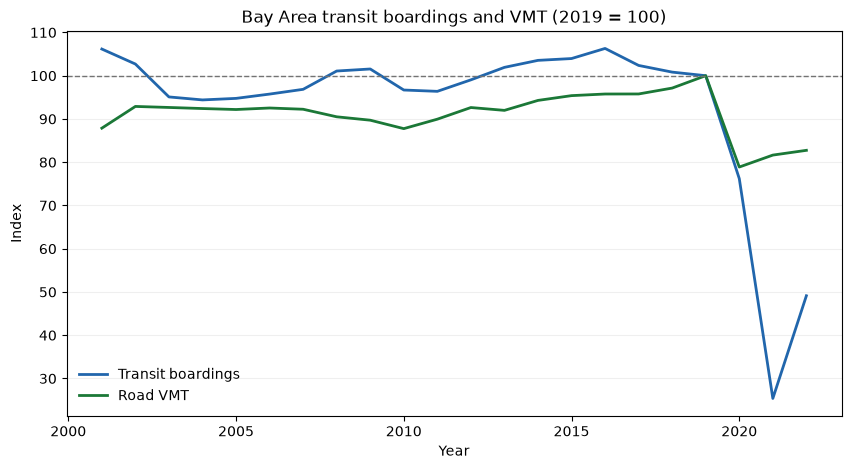

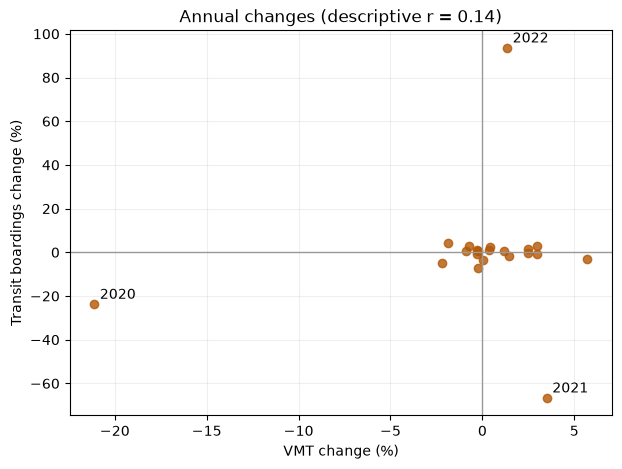

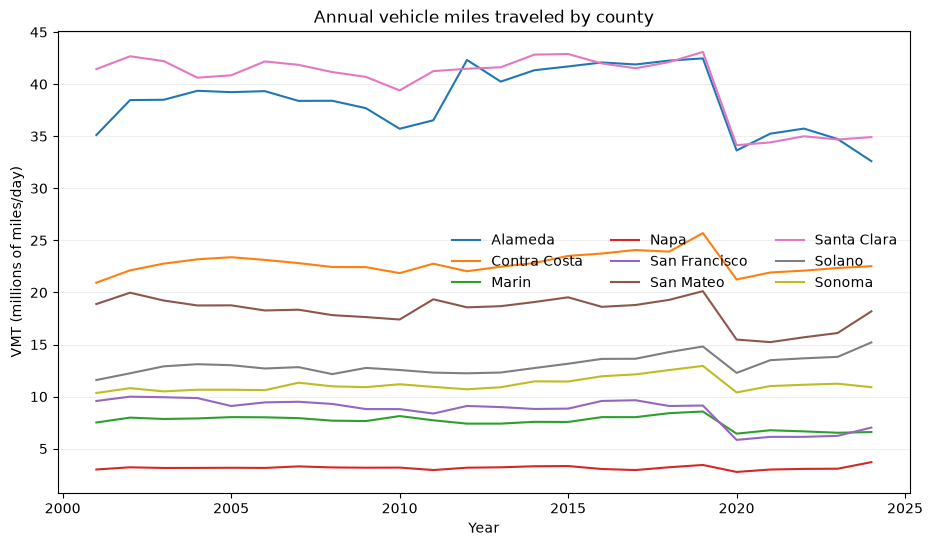

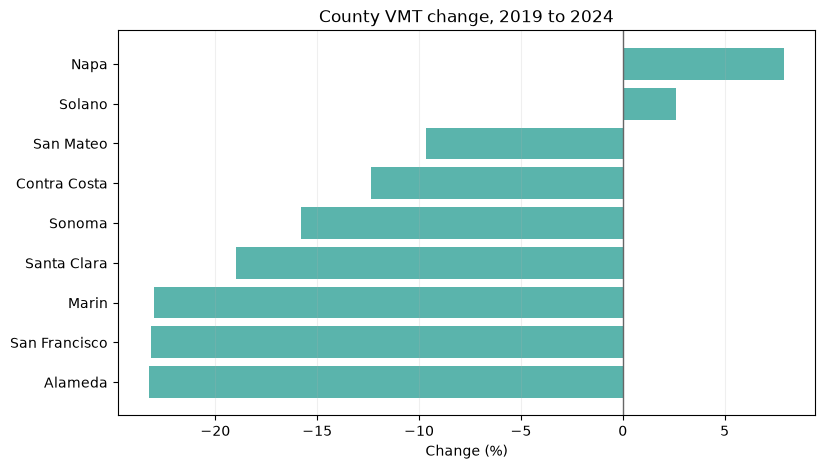

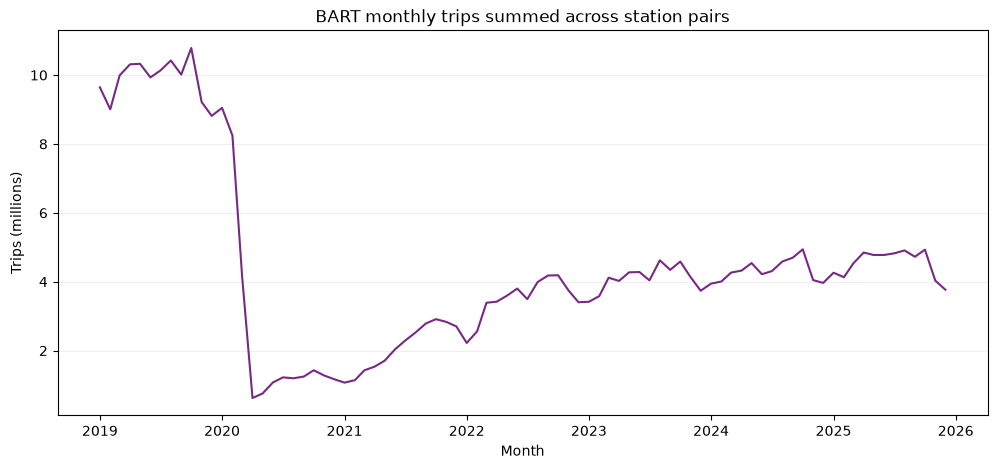

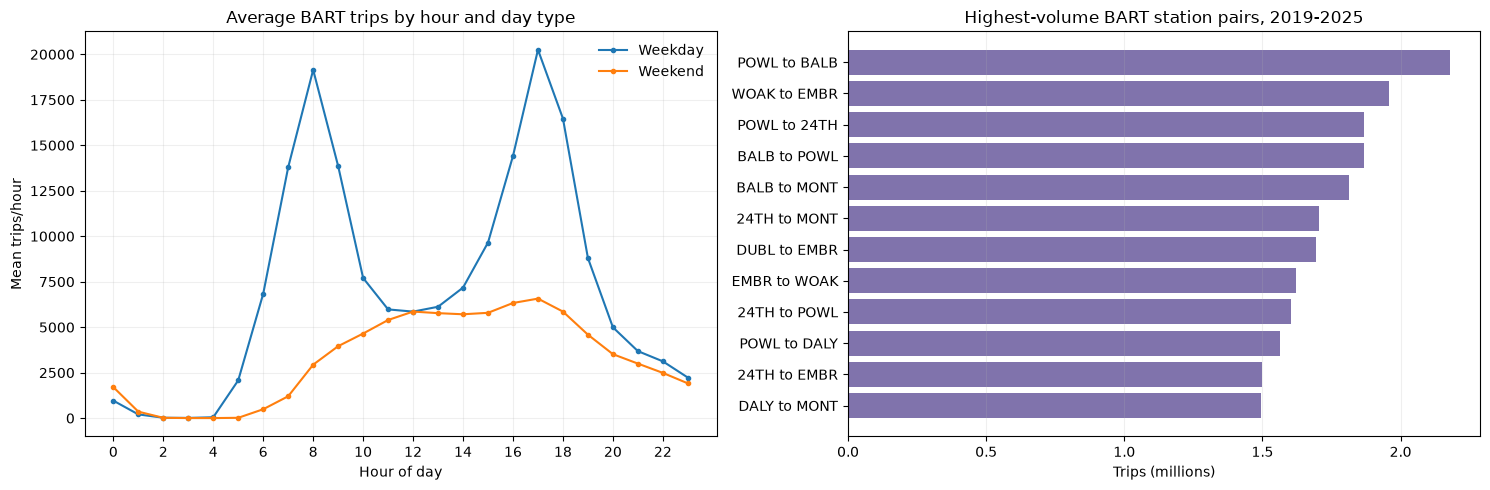

In [16]:
# Regional annual indicators indexed to 2019
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ridership_vmt["year"], ridership_vmt["ridership_index_2019"], label="Transit boardings", color="#2166ac", linewidth=2)
ax.plot(ridership_vmt["year"], ridership_vmt["vmt_index_2019"], label="Road VMT", color="#1b7837", linewidth=2)
ax.axhline(100, color="0.45", linewidth=1, linestyle="--")
ax.set(title="Bay Area transit boardings and VMT (2019 = 100)", xlabel="Year", ylabel="Index")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
plt.show()

# Descriptive association between annual percentage changes
scatter_data = ridership_vmt.dropna(subset=["ridership_yoy_pct", "vmt_yoy_pct"])
correlation = scatter_data["ridership_yoy_pct"].corr(scatter_data["vmt_yoy_pct"])
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(scatter_data["vmt_yoy_pct"], scatter_data["ridership_yoy_pct"], color="#b35806", alpha=0.8)
for _, row in scatter_data[scatter_data["year"].isin([2020, 2021, 2022])].iterrows():
    ax.annotate(str(int(row["year"])), (row["vmt_yoy_pct"], row["ridership_yoy_pct"]), xytext=(4, 4), textcoords="offset points")
ax.set(title=f"Annual changes (descriptive r = {correlation:.2f})", xlabel="VMT change (%)", ylabel="Transit boardings change (%)")
ax.axhline(0, color="0.6", linewidth=1)
ax.axvline(0, color="0.6", linewidth=1)
ax.grid(alpha=0.2)
plt.show()

# County VMT time series and 2019-2024 percentage change
fig, ax = plt.subplots(figsize=(11, 6))
for county, group in county_vmt.groupby("county", observed=True):
    ax.plot(group["year"], group["vmt"] / 1_000_000, label=county, linewidth=1.5)
ax.set(title="Annual vehicle miles traveled by county", xlabel="Year", ylabel="VMT (millions of miles/day)")
ax.legend(ncol=3, frameon=False)
ax.grid(axis="y", alpha=0.2)
plt.show()

county_window = county_vmt[county_vmt["year"].isin([2019, 2024])].pivot(index="county", columns="year", values="vmt")
if {2019, 2024}.issubset(county_window.columns):
    county_window["change_pct"] = (county_window[2024] / county_window[2019] - 1) * 100
    county_window = county_window.sort_values("change_pct")
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(county_window.index, county_window["change_pct"], color="#5ab4ac")
    ax.axvline(0, color="0.4", linewidth=1)
    ax.set(title="County VMT change, 2019 to 2024", xlabel="Change (%)", ylabel="")
    ax.grid(axis="x", alpha=0.2)
    plt.show()

# BART monthly station-pair totals
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(bart_monthly_total["month_start"], bart_monthly_total["trips"] / 1_000_000, color="#762a83", linewidth=1.5)
ax.set(title="BART monthly trips summed across station pairs", xlabel="Month", ylabel="Trips (millions)")
ax.grid(axis="y", alpha=0.2)
plt.show()

# BART weekday/weekend hourly profile and top OD station pairs
hourly = datasets["bart_hourly_profile"].sort_values("hour")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for day_type, group in hourly.groupby("day_type", observed=True):
    axes[0].plot(group["hour"], group["mean_hourly_trips"], marker="o", markersize=3, label=day_type.title())
axes[0].set(title="Average BART trips by hour and day type", xlabel="Hour of day", ylabel="Mean trips/hour")
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.2)

pairs = bart_top_pairs.head(12).sort_values("trips")
pair_labels = pairs["origin_station"] + " to " + pairs["destination_station"]
axes[1].barh(pair_labels, pairs["trips"] / 1_000_000, color="#8073ac")
axes[1].set(title="Highest-volume BART station pairs, 2019-2025", xlabel="Trips (millions)", ylabel="")
axes[1].grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## 10. Data quality assertions

Checks cover duplicate natural keys, nonnegative trips/VMT, expected date coverage, nine-county coverage, and plausible row counts. The survey has intentionally sparse responses across its many questionnaire fields, so its null-rate threshold is looser and should not be read as data loss.

In [17]:
# Natural-key and value checks
assert not bart_od.duplicated(["year_month", "origin_station", "destination_station"]).any()
assert bart_od[["year_month", "origin_station", "destination_station", "trips"]].notna().all().all()
assert (bart_od["trips"] >= 0).all()
assert bart_od["year"].min() == 2019 and bart_od["year"].max() == 2025
assert bart_od["year_month"].min() == "2019-01" and bart_od["year_month"].max() == "2025-12"
assert not ridership_vmt["year"].duplicated().any()
assert (ridership_vmt[["annual_boardings", "vmt", "vmt_per_capita"]] > 0).all().all()
assert not county_vmt.duplicated(["county", "year"]).any()
assert county_vmt["county"].nunique() == 9
assert (county_vmt["vmt"] >= 0).all()
assert 700 <= len(datasets["sfmta_travel_decision_survey_2021"]) <= 800
survey_null_rate = datasets["sfmta_travel_decision_survey_2021"].isna().to_numpy().mean()
assert survey_null_rate < 0.75
assert len(datasets["mtc_transit_ridership_by_operator"]) > 500
assert len(datasets["mtc_transit_ridership_by_mode"]) > 100
assert not datasets["bart_hourly_profile"].duplicated(["day_type", "hour"]).any()
assert (datasets["bart_hourly_profile"]["mean_hourly_trips"] >= 0).all()

quality_summary = pd.DataFrame([
    {"check": "BART monthly station-pair natural key", "status": "passed", "detail": f"{len(bart_od):,} rows, 2019-01 to 2025-12"},
    {"check": "MTC annual indicator overlap", "status": "passed", "detail": f"{len(ridership_vmt)} years, {ridership_vmt['year'].min()}-{ridership_vmt['year'].max()}"},
    {"check": "County VMT coverage", "status": "passed", "detail": f"{county_vmt['county'].nunique()} counties, 2001-2024"},
    {"check": "SFMTA survey", "status": "passed", "detail": f"{len(datasets['sfmta_travel_decision_survey_2021'])} rows; {survey_null_rate:.1%} cells missing across sparse questionnaire fields"},
])
display(quality_summary)

,check,status,detail
0,BART monthly station-pair natural key,passed,"206,725 rows, 2019-01 to 2025-12"
1,MTC annual indicator overlap,passed,"22 years, 2001-2022"
2,County VMT coverage,passed,"9 counties, 2001-2024"
3,SFMTA survey,passed,756 rows; 61.0% cells missing across sparse qu...


## 11. Write curated outputs

Save analysis-ready annual, monthly, county, station-pair, hourly-profile, and dataset-overview tables in `data/curated/` as both Parquet and CSV. Base source Parquets remain unchanged in `data/`.

In [10]:
curated = {
    "annual_ridership_vmt": ridership_vmt,
    "bart_monthly_total": bart_monthly_total,
    "bart_monthly_od": bart_od,
    "bart_top_station_pairs": bart_top_pairs,
    "bart_hourly_profile": datasets["bart_hourly_profile"],
    "county_vmt": county_vmt,
    "dataset_overview": overview,
    "data_quality_checks": quality_summary,
}

for name, frame in curated.items():
    parquet_path = OUTPUT_DIR / f"{name}.parquet"
    csv_path = OUTPUT_DIR / f"{name}.csv"
    frame.to_parquet(parquet_path, index=False)
    frame.to_csv(csv_path, index=False)

output_inventory = []
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        output_inventory.append({"file": path.name, "size_mb": round(path.stat().st_size / (1024 ** 2), 3)})

display(pd.DataFrame(output_inventory))
print("Sample annual comparison:")
display(pd.read_parquet(OUTPUT_DIR / "annual_ridership_vmt.parquet").tail())
print(f"Curated outputs written to {OUTPUT_DIR}")

,file,size_mb
0,annual_ridership_vmt.csv,0.003
1,annual_ridership_vmt.parquet,0.007
2,bart_hourly_profile.csv,0.002
3,bart_hourly_profile.parquet,0.004
4,bart_monthly_od.csv,25.526
5,bart_monthly_od.parquet,0.430
6,bart_monthly_total.csv,0.002
7,bart_monthly_total.parquet,0.004
8,bart_top_station_pairs.csv,0.000
9,bart_top_station_pairs.parquet,0.003


Sample annual comparison:


,year,annual_boardings,estimated_weekday_boardings,vmt,vmt_per_capita,ridership_yoy_pct,vmt_yoy_pct,ridership_index_2019,vmt_index_2019
17,2018,505200897.0,1684003.0,175123707.0,22.640466,-1.506449,1.423488,100.826509,97.137889
18,2019,501059594.0,1670199.0,180283624.0,23.276763,-0.819734,2.946441,100.000000,100.000000
19,2020,381791848.0,1272639.0,142214864.0,18.313348,-23.803106,-21.116039,76.196894,78.883961
20,2021,127199603.0,423999.0,147193637.0,19.128997,-66.683520,3.500881,25.386123,81.645595
21,2022,246151830.0,820506.0,149175562.1,19.618567,93.516194,1.346475,49.126258,82.744932


Curated outputs written to /home/uttam/Dropbox/Projects/mass_transit_analysis/mass-transit-analysis/data/curated
